In [1]:
%load_ext autoreload
%autoreload 2

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [ ]:
# Load data with labels
data_folder = os.path.join(os.getcwd(), "..", "data")

df_female = pd.read_parquet(os.path.join(data_folder, "female_argus_data.parquet"))

df_male = pd.read_parquet(os.path.join(data_folder, "male_argus_data.parquet"))

df = pd.concat([df_female, df_male])

### Drop rows with > 80% missingness

In [3]:
def drop_high_missing_rows(df, threshold=0.8):  # noqa: D103
    df = df.copy()
    df["missing_fraction"] = df.isnull().mean(axis=1)
    df = df.loc[df["missing_fraction"] <= threshold]  # drop rows with more than threshold fraction of missing values
    return df


print("female data set: ")
print(df_female.shape)
df_female = drop_high_missing_rows(df_female)
print(df_female.shape)
print("\n")

print("male dataset:")
print(df_male.shape)
df_male = drop_high_missing_rows(df_male)
print(df_male.shape)



female data set: 
(2737, 39)
(2626, 40)


male dataset:
(3595, 39)
(3364, 40)


In [4]:
# patient characteristics after dropping rows with high missing values
print(f"Number of female patients: {df_female['studyId_0888'].nunique()}")
print(f"Number of male patients: {df_male['studyId_0888'].nunique()}")
print(f"Total number of patients: {df_female['studyId_0888'].nunique() + df_male['studyId_0888'].nunique()}")

print(
    " percentage of female patients: ",
    df_female["studyId_0888"].nunique()
    / (df_male["studyId_0888"].nunique() + df_female["studyId_0888"].nunique())
    * 100,
)

print("Number of visits in the data: "
      f"{len(df_female) + len(df_male)}")


Number of female patients: 2512
Number of male patients: 3243
Total number of patients: 5755
 percentage of female patients:  43.64900086880973
Number of visits in the data: 5990


In [5]:
# Concatenate dataframes df_female and df_male
df = pd.concat([df_female, df_male], ignore_index=True)

In [6]:
df.label.value_counts()

label
0    4171
1    1819
Name: count, dtype: int64

In [7]:
# print mean and std of age per gender
print("Mean of female age:", df_female["Age"].mean())
print("Std of female age:", df_female["Age"].std())
print("Mean of Male age:", df_male["Age"].mean())
print("Std of Male age:", df_male["Age"].std())

Mean of female age: 56.70830159939071
Std of female age: 17.9103860161547
Mean of Male age: 54.508620689655174
Std of Male age: 16.702828002372417


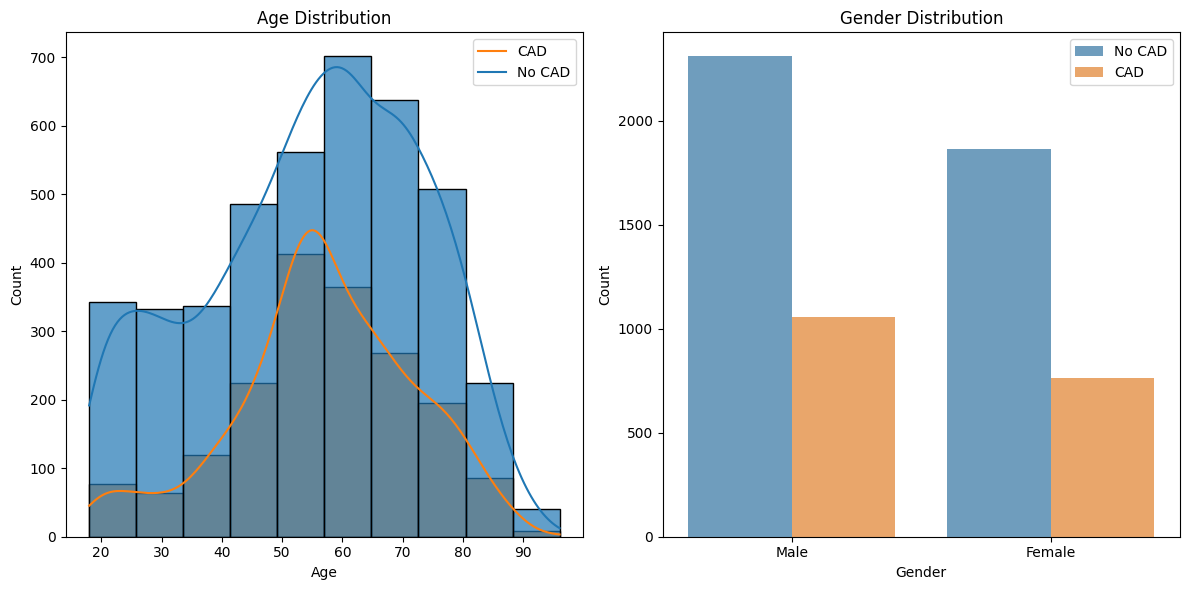

Number of patients: 5755
number of entries: 5990


In [8]:
# META DATA ANALYSIS
# plot gender and age distribution with label as hue
plt.figure(figsize=(12, 6))

label_order = [0, 1]  # 0 = No CAD, 1 = CAD

# Age distribution with label hue
plt.subplot(1, 2, 1)
sns.histplot(data=df, x="Age", hue="label", bins=10, alpha=0.7, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend(
    [
        "CAD",
        "No CAD",
    ]
)

# Gender distribution with label hue
plt.subplot(1, 2, 2)
sns.countplot(data=df, x="gender", hue="label", alpha=0.7, hue_order=label_order)
plt.xticks([0, 1], ["Male", "Female"])
plt.xticks([0, 1], ["Male", "Female"])
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["No CAD", "CAD"], loc="upper right", frameon=True)


plt.tight_layout()
plt.show()

# print value_counts for gender and label combination
pd.crosstab(df["gender"], df["label"], margins=True)

print(f"Number of patients: {df['studyId_0888'].nunique()}")
print(f"number of entries: {len(df)}")


In [9]:
# total missingness:
print(df["studyId_0888"].count())

missingness_summary = df.isna().agg(["sum", "mean"]).T.rename(columns={"sum": "n_missing", "mean": "pct_missing"})

missingness_summary["pct_missing"] *= 100
missingness_summary.to_csv("../data/missingness_summary_trainingdata.csv")


5990


### Prepare data for training:

In [10]:
# Split data into train/val/test sets:
from sklearn.model_selection import train_test_split


def split_data_with_validation(df):
    """Split the DataFrame into training, validation, and testing sets by unique patient."""
    # Ensure splitting is done by unique patients to avoid data leakage
    df_unique = df.drop_duplicates(subset=["studyId_0888"])

    # First split: separate test set (15%)
    train_val_patients, test_patients = train_test_split(df_unique["studyId_0888"], test_size=0.15, random_state=42)

    # Second split: separate validation set from remaining data
    train_patients, val_patients = train_test_split(train_val_patients, test_size=0.1, random_state=42)

    # Select data for train, validation, and test sets based on unique patients
    df_train = df[df["studyId_0888"].isin(train_patients)]
    df_val = df[df["studyId_0888"].isin(val_patients)]
    df_test = df[df["studyId_0888"].isin(test_patients)]

    # For group-based cross-validation, we use the studyId col as the group identifier
    groups_train = df_train["studyId_0888"]
    groups_val = df_val["studyId_0888"]

    # Generate X and y for train, validation, and test sets:
    exclude_cols = ["studyId_0888", "index_dt", "label", "gender", "missing_fraction"]
    label_col = "label"

    # For training set
    X_train = df_train.drop(columns=exclude_cols)  # noqa: N806
    y_train = df_train[label_col]

    # For validation set
    X_val = df_val.drop(columns=exclude_cols)  # noqa: N806
    y_val = df_val[label_col]

    # For test set
    X_test = df_test.drop(columns=exclude_cols)  # noqa: N806
    y_test = df_test[label_col]

    return X_train, y_train, X_val, y_val, X_test, y_test, groups_train, groups_val, test_patients


# Female data
(X_train_f, y_train_f, X_val_f, y_val_f, X_test_f, y_test_f, groups_train_f, groups_val_f, test_patients_f) = (
    split_data_with_validation(df_female)
)

# Male data
(X_train_m, y_train_m, X_val_m, y_val_m, X_test_m, y_test_m, groups_train_m, groups_val_m, test_patients_m) = (
    split_data_with_validation(df_male)
)

In [11]:
train_IDs = np.append(groups_train_f, groups_val_f)
train_IDs = np.append(train_IDs, groups_train_m)
train_IDs = np.append(train_IDs, groups_val_m).tolist()
pd.Series(train_IDs).to_csv("../data/models/train_patients.csv", index=False)
print(len(train_IDs))

5093


In [12]:
# save patients used for testing to csv
test_IDs = np.append(test_patients_f, test_patients_m).tolist()
pd.Series(test_IDs).to_csv("../data/models/test_patients.csv", index=False)
print(len(test_IDs))

864


# Train model 

In [13]:
from sklearn.impute import KNNImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


## Define scorers
We want to predict which patients with chest pain have a <15% risk of CAD (class 0 = No CAD) vs a >=15% risk of CAD (class 1 = possible CAD). 
It is important that we do not miss any patients who have a high risk of CAD and predict them as No CAD, therefore the False Negative Class is most important. This can be assessed by the metric Negative Predictive Value (NPV) = TN/(TN+FN). 
Secondly, it is also important that not everyone is classified as possible CAD, because we aim to minimize the unnecassary diagnostics performed. This can be assessed by the specificity = TN/(TN+FP). 

Hence, we will create an inverted F1 score, which will take into account the NPV and specificity:

inverted_f1 = 2 * (npv * specificity) / (npv + specificity)

In [14]:
from sklearn.metrics import make_scorer


def inverted_f1_score(y_true, y_pred):
    """Calculate the inverted F1 score."""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0

    return 2 * (npv * specificity) / (npv + specificity) if (npv + specificity) > 0 else 0


def negative_predictive_value(y_true, y_pred):
    """Calculate the negative predictive value."""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    return tn / (tn + fn) if (tn + fn) > 0 else 0


def specificity(y_true, y_pred):
    """Calculate the specificity."""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))

    return tn / (tn + fp) if (tn + fp) > 0 else 0


inverted_f1_scorer = make_scorer(inverted_f1_score)
npv_scorer = make_scorer(negative_predictive_value)
specificity_scorer = make_scorer(specificity)

## Define evaluation functions

In [15]:
# From code Malin:
def eval_pred(pred, y, verbose=False):
    """Evaluate predicted probabilities and return classification metrics."""
    rounded = np.round(pred)

    AUC = roc_auc_score(y, pred)  # noqa: N806
    ACC = accuracy_score(y, rounded)  # noqa: N806
    F1 = f1_score(y, rounded)  # noqa: N806
    GINI = AUC * 2 - 1  # noqa: N806

    conf_matrix = confusion_matrix(y, rounded)
    if verbose:
        class_report = classification_report(y, rounded)
        print("<>" * 30)
        print("AUC: {}".format(AUC))
        print("GINI: {}".format(GINI))
        print("F1: {}".format(F1))
        print("ACCURACY: {}".format(ACC))

        print(class_report)
        print("-+" * 30)
        print(conf_matrix)  # (tn, fp, fn, tp)
        print("+" * 30)
    else:
        class_report = classification_report(y, rounded)
    return AUC, ACC, F1, GINI, class_report


def plot_roc_curve(y_prob, y_true, name, title="", ax=None):
    """Plot an ROC curve and optionally save it to a file."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 10))
    fpr, tpr, threshold = roc_curve(y_true, y_prob)

    ax.set_title("Receiver Operating Characteristic: {}".format(title))
    ax.plot(fpr, tpr, "black")  # , label = 'AUC = %0.2f' % roc_auc)
    # ax.legend(loc = 'lower right')
    ax.plot([0, 1], [0, 1], "r--")
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])
    ax.set_ylabel("True Positive Rate")
    ax.set_xlabel("False Positive Rate")

    if name is not None:
        plt.savefig(name)

In [16]:
def evaluate_model_comprehensive(model, X_test, y_test):
    """Evaluate the model on test data and return predicted probabilities and metrics."""
    # Predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]  # proba of positive class

    # Confusion matrix components
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    # Calculate all metrics
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0  # Negative Predictive Value
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0  # Precision/Positive Predictive Value
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0  # Recall
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    inverted_f1 = inverted_f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred)

    print(" ###### Model Evaluation ######")
    print(f"Negative Predictive Value (NPV): {npv:.4f}")
    print(f"PPV (Precision): {ppv:.4f}")
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"Balanced Accuracy: {(sensitivity + specificity) / 2:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")
    print(f"Inverted F1 Score: {inverted_f1:.4f}")
    print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print("\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred))

    return y_proba, {
        "npv": npv,
        "ppv": ppv,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "inverted_f1": inverted_f1,
        "roc_auc": roc_auc,
        "confusion_matrix": (tn, fp, fn, tp),
    }


In [17]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
)
from statsmodels.stats.proportion import proportion_confint
from tabulate import tabulate


def bootstrap_auc_ci(y_true, y_score, metric_func, n_bootstraps=1000, alpha=0.05, random_state=42):
    """Percentile bootstrap CI for a ranking metric (AUROC, AUPRC, etc.)."""
    rng = np.random.RandomState(random_state)
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    n = len(y_true)

    scores = []
    for _ in range(n_bootstraps):
        idx = rng.randint(0, n, n)
        y_true_bs = y_true[idx]
        y_score_bs = y_score[idx]
        if len(np.unique(y_true_bs)) < 2:  # skip resamples with only one class
            continue
        scores.append(metric_func(y_true_bs, y_score_bs))

    scores = np.array(scores)
    lower = np.percentile(scores, 100 * alpha / 2)
    upper = np.percentile(scores, 100 * (1 - alpha / 2))
    return lower, upper


def evaluate_model_comprehensive_pred(y_pred, y_test, y_proba=None, alpha=0.05, n_bootstraps=1000, verbose=True):
    """Compute classification metrics with confidence intervals.

    Returns a dict: {metric_name: (value, ci_lower, ci_upper_or_None)}.
    """
    y_pred = np.asarray(y_pred)
    y_test = np.asarray(y_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    n_total = tn + fp + fn + tp

    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    balanced_acc = (sensitivity + specificity) / 2
    inverted_f1 = inverted_f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)

    score_for_ranking = y_proba if y_proba is not None else y_pred
    roc_auc = roc_auc_score(y_test, score_for_ranking)
    auprc = average_precision_score(y_test, score_for_ranking)

    def wilson_ci(count, nobs):
        if nobs == 0:
            return (0, 0)
        return proportion_confint(count=count, nobs=nobs, alpha=alpha, method="wilson")

    npv_ci = wilson_ci(tn, tn + fn)
    ppv_ci = wilson_ci(tp, tp + fp)
    sens_ci = wilson_ci(tp, tp + fn)
    spec_ci = wilson_ci(tn, tn + fp)
    bal_acc_ci = ((sens_ci[0] + spec_ci[0]) / 2, (sens_ci[1] + spec_ci[1]) / 2)
    acc_ci = wilson_ci(tn + tp, n_total)

    roc_auc_ci = bootstrap_auc_ci(y_test, score_for_ranking, roc_auc_score, n_bootstraps=n_bootstraps, alpha=alpha)
    auprc_ci = bootstrap_auc_ci(
        y_test, score_for_ranking, average_precision_score, n_bootstraps=n_bootstraps, alpha=alpha
    )

    results = {
        "ROC AUC": (roc_auc, *roc_auc_ci),
        "AUPRC": (auprc, *auprc_ci),
        "Sensitivity (Recall)": (sensitivity, *sens_ci),
        "Specificity": (specificity, *spec_ci),
        "PPV (Precision)": (ppv, *ppv_ci),
        "NPV": (npv, *npv_ci),
        "Balanced Accuracy": (balanced_acc, *bal_acc_ci),
        "Accuracy": (acc, *acc_ci),
        "Inverted F1": (inverted_f1, np.nan, np.nan),  # no CI computed for this metric
        "TN": (tn, np.nan, np.nan),
        "FP": (fp, np.nan, np.nan),
        "FN": (fn, np.nan, np.nan),
        "TP": (tp, np.nan, np.nan),
    }

    if verbose:
        table_data = [
            [name, f"{val:.2f} ({lo:.2f}–{hi:.2f})" if not np.isnan(lo) else f"{val:.2f}"]
            for name, (val, lo, hi) in results.items()
            if name not in ("TN", "FP", "FN", "TP")
        ]
        print("=== Model Evaluation ===\n")
        print(tabulate(table_data, headers=["Metric", "Value (95% CI)"], tablefmt="grid"))
        print(f"\nConfusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
        print("\nDetailed Classification Report:")
        print(classification_report(y_test, y_pred))

    return results

In [18]:
from sklearn.calibration import calibration_curve


def plot_calibration_curve(y_true, y_proba, n_bins=10):
    """Plot calibration curve for predicted probabilities."""
    fraction_of_positives, mean_predicted_value = calibration_curve(y_true, y_proba, n_bins=n_bins)

    plt.figure(figsize=(8, 6))
    plt.plot(mean_predicted_value, fraction_of_positives, "s-", label="Calibration Curve")
    plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Fraction of Positives")
    plt.title("Calibration Curve")
    plt.legend()
    plt.grid()
    plt.show()


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss
from statsmodels.nonparametric.smoothers_lowess import lowess

In [20]:
def plot_calibration_curve_smoothed(groups, method="loess", frac=0.6667, show_ci=True, n_bootstraps=200, alpha=0.05):  # noqa: D417
    """Plot smoothed calibration curves (LOESS) for multiple groups on one figure.

    Prints calibration intercept, slope, and Brier score per group.

    Parameters
    ----------
    groups : dict
        group_name -> (y_true, y_proba, color)
    method : {'loess'}
        Smoothing method. Currently LOESS; RCS can be added if needed.
    frac : float
        LOESS smoothing span (fraction of data used per local fit).
        Lower = wigglier/more local, higher = smoother. 0.3-0.7 is typical.
    show_ci : bool
        If True, adds a bootstrap confidence band around each smoothed curve.
    n_bootstraps : int
        Number of bootstrap resamples for the confidence band.

    """
    plt.figure(figsize=(8, 6))
    results = {}

    for name, (y_true, y_proba, color) in groups.items():
        y_true = np.asarray(y_true)
        y_proba = np.asarray(y_proba)

        # sort by predicted probability for a clean line
        order = np.argsort(y_proba)
        x_sorted, y_sorted = y_proba[order], y_true[order]

        smoothed = lowess(y_sorted, x_sorted, frac=frac, return_sorted=True)
        x_smooth, y_smooth = smoothed[:, 0], smoothed[:, 1]

        # calibration intercept/slope (same as before, unaffected by plot smoothing choice)
        eps = 1e-6
        p_clip = np.clip(y_proba, eps, 1 - eps)
        logit_p = np.log(p_clip / (1 - p_clip))
        X = sm.add_constant(logit_p)  # noqa: N806
        model = sm.Logit(y_true, X).fit(disp=0)
        intercept, slope = model.params[0], model.params[1]
        intercept_ci = tuple(model.conf_int(alpha=alpha)[0])
        slope_ci = tuple(model.conf_int(alpha=alpha)[1])

        brier = brier_score_loss(y_true, y_proba)

        print(f"=== Calibration Metrics: {name} (LOESS frac={frac}) ===")
        print(
            f"Calibration Intercept (ideal=0): {intercept:.3f} "
            f"(95% CI: {intercept_ci[0]:.3f}\u2013{intercept_ci[1]:.3f})"
        )
        print(f"Calibration Slope (ideal=1):     {slope:.3f} (95% CI: {slope_ci[0]:.3f}\u2013{slope_ci[1]:.3f})")
        print(f"Brier Score (lower=better):      {brier:.4f}\n")

        # optional bootstrap confidence band around the LOESS curve
        if show_ci:
            rng = np.random.RandomState(42)
            n = len(y_true)
            eval_x = np.linspace(x_sorted.min(), x_sorted.max(), 200)
            boot_curves = []
            for _ in range(n_bootstraps):
                idx = rng.randint(0, n, n)
                xb, yb = y_proba[idx], y_true[idx]
                order_b = np.argsort(xb)
                sm_b = lowess(yb[order_b], xb[order_b], frac=frac, return_sorted=True)
                interp = np.interp(eval_x, sm_b[:, 0], sm_b[:, 1])
                boot_curves.append(interp)
            boot_curves = np.array(boot_curves)
            lower = np.percentile(boot_curves, 100 * alpha / 2, axis=0)
            upper = np.percentile(boot_curves, 100 * (1 - alpha / 2), axis=0)
            plt.fill_between(eval_x, lower, upper, color=color, alpha=0.15)

        plt.plot(x_smooth, y_smooth, "-", label=name, color=color, linewidth=2)

        results[name] = {
            "calibration_intercept": intercept,
            "calibration_intercept_ci": intercept_ci,
            "calibration_slope": slope,
            "calibration_slope_ci": slope_ci,
            "brier_score": brier,
        }

    plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
    plt.xlabel("Predicted Probability")
    plt.ylabel("Observed Probability (LOESS smoothed)")
    plt.title("Calibration Curve (smoothed)")
    plt.legend()
    plt.grid()
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.show()

    return results

In [21]:
# Since we will use cross validation, there is no need for a separate validation set.
x_full_f = pd.concat([X_train_f, X_val_f], ignore_index=True)
y_full_f = pd.concat([y_train_f, y_val_f], ignore_index=True)
groups_full_f = pd.concat([groups_train_f, groups_val_f], ignore_index=True)

x_full_m = pd.concat([X_train_m, X_val_m], ignore_index=True)
y_full_m = pd.concat([y_train_m, y_val_m], ignore_index=True)
groups_full_m = pd.concat([groups_train_m, groups_val_m], ignore_index=True)


## Set baseline model:

In [22]:
# Create baseline prediction (classify all as 0)
baseline_pred = np.zeros(len(y_train_f))


def baseline_evaluation_metrics(y_test, y_pred):  # noqa: D103
    acc = accuracy_score(y_test, y_pred)
    inv_f1 = inverted_f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred)
    return acc, inv_f1, auc


acc, inv_f1, AUC = baseline_evaluation_metrics(y_train_f, baseline_pred)

print(f"Baseline (all 0) accuracy: {acc:.3f} ({acc * 100:.1f}%)")
print(f"Baseline inverted F1 score: {inv_f1:.3f}")
print(f"Baseline AUC ROC: {AUC:.3f}")
print(f"Bsaline Negative Predictive Value: {negative_predictive_value(y_train_f, baseline_pred):.3f}")
print(f"Percentage of actual 0s in test set: {(y_train_f == 0).mean() * 100:.1f}%")
print(f"Percentage of actual 1s in test set: {(y_train_f == 1).mean() * 100:.1f}%")

Baseline (all 0) accuracy: 0.710 (71.0%)
Baseline inverted F1 score: 0.831
Baseline AUC ROC: 0.500
Bsaline Negative Predictive Value: 0.710
Percentage of actual 0s in test set: 71.0%
Percentage of actual 1s in test set: 29.0%


In [23]:
# --- Baseline: classify everyone as 0 ---
baseline_pred_male = np.zeros(len(y_train_m))
baseline_pred_female = np.zeros(len(y_train_f))

# Run all four evaluations (verbose=False to suppress the per-group printout)
runs = {
    "Male_baseline": (baseline_pred_male, y_train_m, None),
    "Female_baseline": (baseline_pred_female, y_train_f, None),
}

all_results = {
    name: evaluate_model_comprehensive_pred(y_pred, y_test, y_proba, verbose=False)
    for name, (y_pred, y_test, y_proba) in runs.items()
}


def format_value_ci(value, ci_lo, ci_hi):  # noqa: D103
    if np.isnan(ci_lo) or np.isnan(ci_hi):
        return f"{value:.2f}"
    return f"{value:.2f} ({ci_lo:.2f}\u2013{ci_hi:.2f})"


records = {
    group: {metric_name: format_value_ci(value, ci_lo, ci_hi) for metric_name, (value, ci_lo, ci_hi) in metrics.items()}
    for group, metrics in all_results.items()
}

df_metrics_wide = pd.DataFrame(records)
df_metrics_wide.index.name = "Metric"

# df_metrics_wide.to_csv("model_evaluation_metrics_wide.csv")
df_metrics_wide

,Male_baseline,Female_baseline
Metric,,
ROC AUC,0.50 (0.50–0.50),0.50 (0.50–0.50)
AUPRC,0.32 (0.30–0.34),0.29 (0.27–0.31)
Sensitivity (Recall),0.00 (0.00–0.00),0.00 (0.00–0.01)
Specificity,1.00 (1.00–1.00),1.00 (1.00–1.00)
PPV (Precision),0.00 (0.00–0.00),0.00 (0.00–0.00)
NPV,0.68 (0.66–0.70),0.71 (0.69–0.73)
Balanced Accuracy,0.50 (0.50–0.50),0.50 (0.50–0.50)
Accuracy,0.68 (0.66–0.70),0.71 (0.69–0.73)
Inverted F1,0.81,0.83


### Train logistic regression as baseline

In [24]:
# logistic regression model as baseline
from sklearn.linear_model import LogisticRegression

# Calculate scale_pos_weight for imbalanced classes
class_counts_f = np.bincount(y_train_f)
scale_weight_f = class_counts_f[0] / class_counts_f[1]

# Create pipeline
pipeline_f = Pipeline(
    [
        ("imputer", KNNImputer(n_neighbors=10, weights="distance")),
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(random_state=42, class_weight={1: scale_weight_f}),
        ),
    ]
)

# Calculate scale_pos_weight for imbalanced classes
class_counts_m = np.bincount(y_train_m)
scale_weight_m = class_counts_m[0] / class_counts_m[1]

pipeline_m = Pipeline(
    [
        ("imputer", KNNImputer(n_neighbors=10, weights="distance")),
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(random_state=42, class_weight={1: scale_weight_m}),
        ),
    ]
)

# Train female baseline model
pipeline_f.fit(x_full_f, y_full_f)
y_pred_reg_f = pipeline_f.predict(X_test_f)
y_pred_reg_f_proba = pipeline_f.predict_proba(X_test_f)[:, 1]

# Train male baseline model
pipeline_m.fit(x_full_m, y_full_m)
y_pred_reg_m = pipeline_m.predict(X_test_m)
y_pred_reg_m_proba = pipeline_m.predict_proba(X_test_m)[:, 1]

In [25]:
acc, inv_f1, AUC = baseline_evaluation_metrics(y_test_f, y_pred_reg_f)

print(f"Baseline accuracy: {acc:.3f} ({acc * 100:.1f}%)")
print(f"Baseline inverted F1 score: {inv_f1:.3f}")
print(f"Baseline AUC ROC: {AUC:.3f}")
_, metrics_baseline_f = evaluate_model_comprehensive(pipeline_f, X_test_f, y_test_f)
eval_pred(y_pred_reg_f_proba, y_test_f, verbose=True)

##### MALE data ######
acc, inv_f1, AUC = baseline_evaluation_metrics(y_test_m, y_pred_reg_m)
print(f"Baseline accuracy: {acc:.3f} ({acc * 100:.1f}%)")
print(f"Baseline inverted F1 score: {inv_f1:.3f}")
print(f"Baseline AUC ROC: {AUC:.3f}")
_, metrics_baseline_m = evaluate_model_comprehensive(pipeline_m, X_test_m, y_test_m)
eval_pred(y_pred_reg_m_proba, y_test_m, verbose=True)


Baseline accuracy: 0.495 (49.5%)
Baseline inverted F1 score: 0.574
Baseline AUC ROC: 0.504
 ###### Model Evaluation ######
Negative Predictive Value (NPV): 0.7105
PPV (Precision): 0.2961
Sensitivity (Recall): 0.5259
Specificity: 0.4821
Balanced Accuracy: 0.5040
ROC AUC: 0.5040
Inverted F1 Score: 0.5745
Confusion Matrix: TN=135, FP=145, FN=55, TP=61

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.48      0.57       280
           1       0.30      0.53      0.38       116

    accuracy                           0.49       396
   macro avg       0.50      0.50      0.48       396
weighted avg       0.59      0.49      0.52       396

<><><><><><><><><><><><><><><><><><><><><><><><><><><><><><>
AUC: 0.5237068965517242
GINI: 0.0474137931034484
F1: 0.37888198757763975
ACCURACY: 0.494949494949495
              precision    recall  f1-score   support

           0       0.71      0.48      0.57       280
           1      

(0.6011383368705383,
 0.562874251497006,
 0.45112781954887216,
 0.2022766737410766,
 '              precision    recall  f1-score   support\n\n           0       0.77      0.54      0.64       355\n           1       0.36      0.62      0.45       146\n\n    accuracy                           0.56       501\n   macro avg       0.56      0.58      0.54       501\nweighted avg       0.65      0.56      0.58       501\n')

## Train basic XGBoost model (without hyperparameter tuning)

In [26]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn import set_config
from xgboost import XGBClassifier


def train_xgboost_basic(X_train, y_train, X_test, y_test, groups_train, n_est, booster):
    """Train a basic XGBoost model with cross-validation predictions."""
    # Calculate scale_pos_weight for imbalanced classes
    class_counts = np.bincount(y_train)
    scale_weight = class_counts[0] / class_counts[1]

    # Create the XGBoost model - same parameters as original
    model = XGBClassifier(
        n_estimators=n_est,
        max_depth=5,
        learning_rate=0.1,
        reg_alpha=1,
        reg_lambda=2,
        booster=booster,
        scale_pos_weight=scale_weight,
        random_state=42,
        eval_metric="logloss",
    )

    # Define custom scoring metrics
    scoring = {
        "NPV": npv_scorer,
        "specificity": specificity_scorer,
        "ppv": "precision",  # Positive Predictive Value / Precision
        "sensitivity": "recall",  # Sensitivity/Recall
        "accuracy": "accuracy",
        "inverted_f1": inverted_f1_scorer,
        "roc_auc": "roc_auc",
    }

    # Set up cross-validation strategy
    cv = StratifiedGroupKFold(n_splits=10)

    # Get cross-validation scores
    set_config(enable_metadata_routing=True)
    cv_results = cross_validate(model, X_train, y_train, cv=cv, params={"groups": groups_train}, scoring=scoring)

    # to dataframe
    cv_results = pd.DataFrame(cv_results)

    # Fit model on full training data for test predictions
    model.fit(X_train, y_train)

    # Get predictions on test data
    y_proba_test = model.predict_proba(X_test)[:, 1]

    return model, y_proba_test, cv_results

In [27]:
###### Female data ######
xgb_f, y_proba_f, cv_results_f = train_xgboost_basic(
    x_full_f, y_full_f, X_test_f, y_test_f, groups_full_f, n_est=100, booster="gbtree"
)

xgb_f_10, y_proba_f_10, cv_results_f_10 = train_xgboost_basic(
    x_full_f, y_full_f, X_test_f, y_test_f, groups_full_f, n_est=10, booster="gbtree"
)

##### Male data #####
xgb_m, y_proba_m, cv_results_m = train_xgboost_basic(
    x_full_m, y_full_m, X_test_m, y_test_m, groups_full_m, n_est=100, booster="gbtree"
)

xgb_m_10, y_proba_m_10, cv_results_m_10 = train_xgboost_basic(
    x_full_m, y_full_m, X_test_m, y_test_m, groups_full_m, n_est=10, booster="gbtree"
)

In [28]:
def evaluate_cv_scores(cv_results, model_name):
    """Evaluate cross-validation scores for a specific metric."""
    metric_cols = [col for col in cv_results.columns if col.startswith("test_")]
    metric_names = [col.replace("test_", "") for col in metric_cols]

    # Calculate summary statistics
    summary_data = []
    for col, metric in zip(metric_cols, metric_names, strict=False):
        values = cv_results[col]
        summary_data.append(
            {
                "Metric": metric.upper(),
                "Mean": values.mean(),
                "Std": values.std(),
                "Min": values.min(),
                "Max": values.max(),
                "CV": values.std() / values.mean() * 100,  # Coefficient of variation
                "95% CI Lower": values.mean() - 1.96 * values.std() / np.sqrt(len(values)),
                "95% CI Upper": values.mean() + 1.96 * values.std() / np.sqrt(len(values)),
            }
        )

    summary_df = pd.DataFrame(summary_data)
    summary_df = summary_df.sort_values("Mean", ascending=False)

    # Print formatted summary
    print(f"\n{'=' * 60}")
    print(f"Cross-Validation Results Summary - {model_name}")
    print(f"{'=' * 60}")
    print(f"Number of folds: {len(cv_results)}")
    print("\nMetric Performance:")
    print("-" * 60)

    for _, row in summary_df.iterrows():
        print(
            f"{row['Metric']:15} | Mean: {row['Mean']:.4f} ± {row['Std']:.4f} | "
            f"95% CI: [{row['95% CI Lower']:.4f}, {row['95% CI Upper']:.4f}]"
        )

In [29]:
# print("\n" + "=" * 50 + "\n")
# print("Female XGBoost Model (100 estimators):")
_, metrics_f = evaluate_model_comprehensive(xgb_f, X_test_f, y_test_f)
# evaluate_cv_scores(cv_results_f, "Female XGBoost Model (100 estimators)")


print("\n" + "=" * 50 + "\n")
print("Female XGBoost Model (10 estimators):")
_, metrics_f_10 = evaluate_model_comprehensive(xgb_f_10, X_test_f, y_test_f)
evaluate_cv_scores(cv_results_f_10, "Female XGBoost Model (10 estimators)")


# print("\n" + "=" * 50 + "\n")
# print("Male XGBoost Model (100 estimators):")
_, metrics_m = evaluate_model_comprehensive(xgb_m, X_test_m, y_test_m)
# evaluate_cv_scores(cv_results_m, "Male XGBoost Model (100 estimators)")
# plot_calibration_curve(y_test_m, y_proba_m)

print("\n" + "=" * 50 + "\n")
print("Male XGBoost Model (10 estimators):")
_, metrics_m_10 = evaluate_model_comprehensive(xgb_m_10, X_test_m, y_test_m)
evaluate_cv_scores(cv_results_m_10, "Male XGBoost Model (10 estimators)")
# plot_calibration_curve(y_test_m, y_proba_m_10)

 ###### Model Evaluation ######
Negative Predictive Value (NPV): 0.7947
PPV (Precision): 0.4662
Sensitivity (Recall): 0.5345
Specificity: 0.7464
Balanced Accuracy: 0.6405
ROC AUC: 0.6405
Inverted F1 Score: 0.7698
Confusion Matrix: TN=209, FP=71, FN=54, TP=62

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.75      0.77       280
           1       0.47      0.53      0.50       116

    accuracy                           0.68       396
   macro avg       0.63      0.64      0.63       396
weighted avg       0.70      0.68      0.69       396



Female XGBoost Model (10 estimators):
 ###### Model Evaluation ######
Negative Predictive Value (NPV): 0.8871
PPV (Precision): 0.4524
Sensitivity (Recall): 0.8190
Specificity: 0.5893
Balanced Accuracy: 0.7041
ROC AUC: 0.7041
Inverted F1 Score: 0.7082
Confusion Matrix: TN=165, FP=115, FN=21, TP=95

Detailed Classification Report:
              precision    recall  f1-score   su

In [30]:
# compare metrics of the xgboost and baseline model for female and male data in dataframe
import pandas as pd


def compare_metrics(metrics_xgb, metrics_baseline, metrics_xgb_10, model_type):
    """Compare metrics of XGBoost and baseline models and return a DataFrame."""
    data = {
        "Metric": [
            "Negative Predictive Value (NPV)",
            "PPV (Precision)",
            "Sensitivity (Recall)",
            "Specificity",
            "ROC AUC",
            "Inverted F1 Score",
        ],
        f"Baseline {model_type}": [
            metrics_baseline["npv"],
            metrics_baseline["ppv"],
            metrics_baseline["sensitivity"],
            metrics_baseline["specificity"],
            metrics_baseline["roc_auc"],
            metrics_baseline["inverted_f1"],
        ],
        f"XGBoost {model_type}": [
            metrics_xgb["npv"],
            metrics_xgb["ppv"],
            metrics_xgb["sensitivity"],
            metrics_xgb["specificity"],
            metrics_xgb["roc_auc"],
            metrics_xgb["inverted_f1"],
        ],
        f"XGBoost 10 estimators {model_type}": [
            metrics_xgb_10["npv"],
            metrics_xgb_10["ppv"],
            metrics_xgb_10["sensitivity"],
            metrics_xgb_10["specificity"],
            metrics_xgb_10["roc_auc"],
            metrics_xgb_10["inverted_f1"],
        ],
    }

    return pd.DataFrame(data)


In [31]:
compare_metrics_f = compare_metrics(metrics_f, metrics_baseline_f, metrics_f_10, "female")
compare_metrics_f

,Metric,Baseline female,XGBoost female,XGBoost 10 estimators female
0,Negative Predictive Value (NPV),0.710526,0.794677,0.887097
1,PPV (Precision),0.296117,0.466165,0.452381
2,Sensitivity (Recall),0.525862,0.534483,0.818966
3,Specificity,0.482143,0.746429,0.589286
4,ROC AUC,0.504002,0.640456,0.704126
5,Inverted F1 Score,0.574468,0.769797,0.708155


In [32]:
compare_metrics_m = compare_metrics(metrics_m, metrics_baseline_m, metrics_m_10, "male")
compare_metrics_m

,Metric,Baseline male,XGBoost male,XGBoost 10 estimators male
0,Negative Predictive Value (NPV),0.774194,0.833876,0.843511
1,PPV (Precision),0.355731,0.489691,0.439331
2,Sensitivity (Recall),0.616438,0.650685,0.719178
3,Specificity,0.540845,0.721127,0.622535
4,ROC AUC,0.578642,0.685906,0.670857
5,Inverted F1 Score,0.636816,0.773414,0.716370


## Learning curve



Evaluating model xgb_10 for female data...
Model type: Pipeline


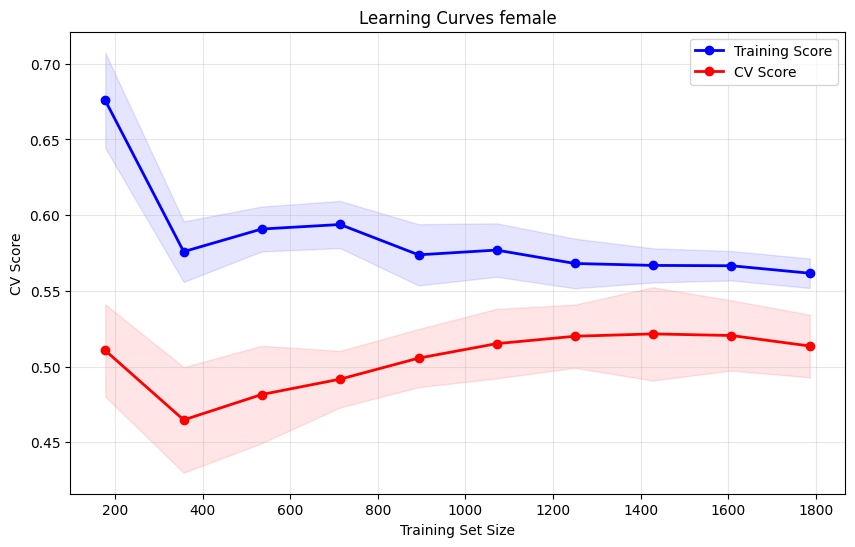

Final training score: 0.5616
Final test score: 0.5135
Final gap: 0.0481 --> if > 0.1 , model is overfitting


Model type: XGBClassifier


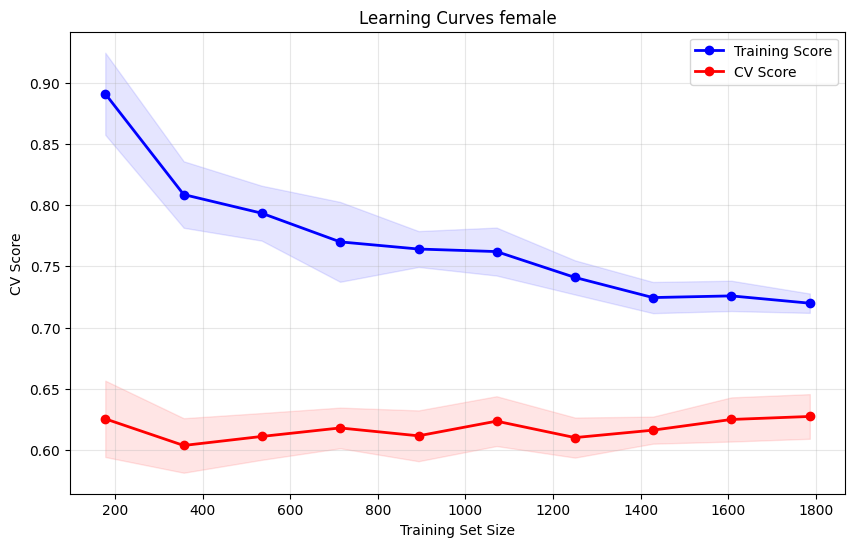

Final training score: 0.7199
Final test score: 0.6274
Final gap: 0.0925 --> if > 0.1 , model is overfitting




Evaluating model xgb_10 for male data...
Model type: Pipeline


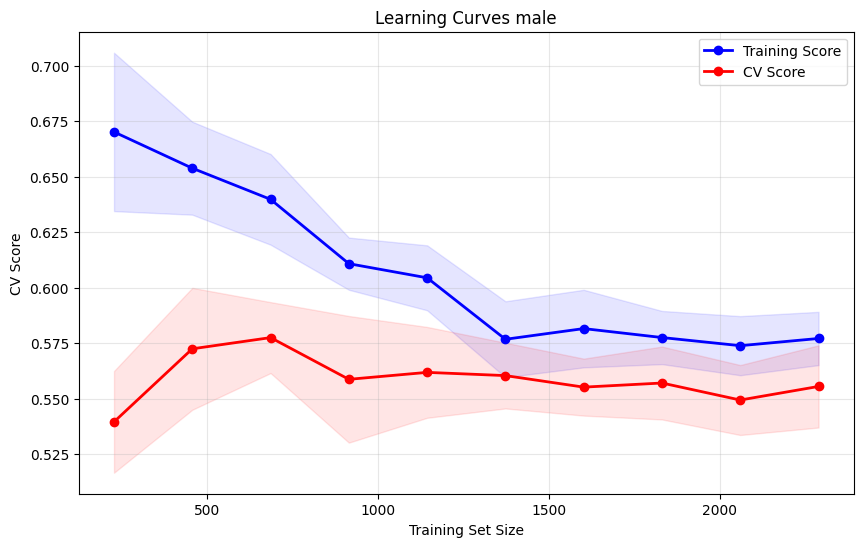

Final training score: 0.5771
Final test score: 0.5555
Final gap: 0.0216 --> if > 0.1 , model is overfitting


Model type: XGBClassifier


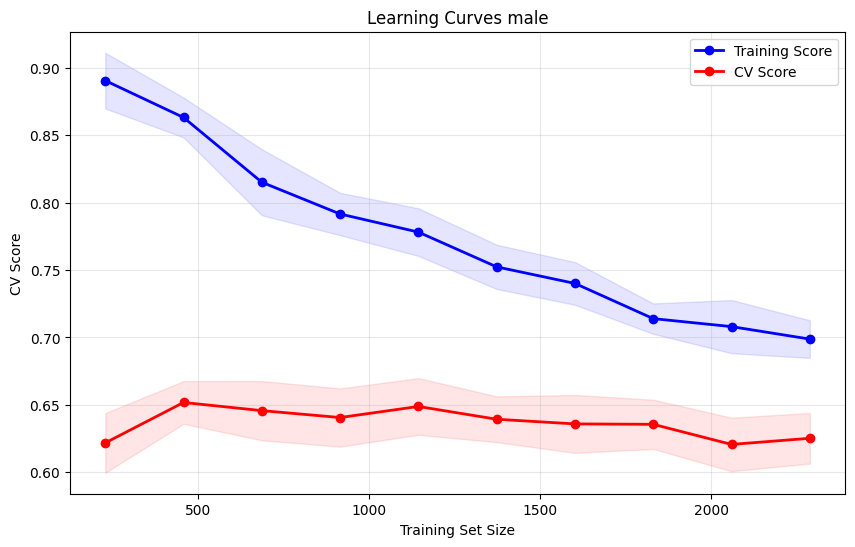

Final training score: 0.6988
Final test score: 0.6252
Final gap: 0.0735 --> if > 0.1 , model is overfitting




In [33]:
import os

from sklearn import set_config
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, learning_curve

# Load the best model and evaluate it
model_types = ["female", "male"]
data_folder = os.path.join(os.getcwd(), "..", "data", "models")

for model_type in model_types:
    if model_type == "female":
        X_train, y_train, X_test, y_test, groups_train, groups_val = (
            x_full_f,
            y_full_f,
            X_test_f,
            y_test_f,
            groups_train_f,
            groups_val_f,
        )

        best_models = [pipeline_f, xgb_f_10]

    elif model_type == "male":
        X_train, y_train, X_test, y_test, groups_train, groups_val = (
            x_full_m,
            y_full_m,
            X_test_m,
            y_test_m,
            groups_train_m,
            groups_val_m,
        )
        best_models = [pipeline_m, xgb_m_10]

    print("\n" + "=" * 50 + "\n")
    print(f"Evaluating model xgb_10 for {model_type} data...")

    for best_model in best_models:
        print(f"Model type: {type(best_model).__name__}")

        y_proba = best_model.predict_proba(X_test)[:, 1]  # proba of positive class

        x_full = X_train.copy()
        y_full = y_train.copy()
        groups_full = pd.concat([groups_train, groups_val])

        set_config(enable_metadata_routing=True)
        cv = GroupShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

        model_clone = clone(best_model)
        train_sizes, train_scores, test_scores = learning_curve(
            model_clone,
            x_full,
            y_full,
            cv=cv,
            params={"groups": groups_full},
            train_sizes=np.linspace(0.1, 1.0, 10),
            n_jobs=-1,
            random_state=42,
        )

        # Calculate means and standard deviations
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        val_mean = np.mean(test_scores, axis=1)
        val_std = np.std(test_scores, axis=1)

        # Plot
        plt.figure(figsize=(10, 6))
        plt.plot(
            train_sizes,
            train_mean,
            "o-",
            color="blue",
            label="Training Score",
            linewidth=2,
        )
        plt.fill_between(
            train_sizes,
            train_mean - train_std,
            train_mean + train_std,
            alpha=0.1,
            color="blue",
        )

        plt.plot(
            train_sizes,
            val_mean,
            "o-",
            color="red",
            label="CV Score",
            linewidth=2,
        )
        plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color="red")

        plt.xlabel("Training Set Size")
        plt.ylabel("CV Score")
        plt.title(f"Learning Curves {model_type}")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

        # Analysis
        final_gap = train_mean[-1] - val_mean[-1]
        gap_trend = np.polyfit(range(len(train_mean)), train_mean - val_mean, 1)[0]

        print(f"Final training score: {train_mean[-1]:.4f}")
        print(f"Final test score: {val_mean[-1]:.4f}")
        print(f"Final gap: {final_gap:.4f} --> if > 0.1 , model is overfitting")

        print("\n" + "=" * 50 + "\n")  # Separator for clarity

## Calibration

 ###### Model Evaluation ######
Negative Predictive Value (NPV): 0.8871
PPV (Precision): 0.4524
Sensitivity (Recall): 0.8190
Specificity: 0.5893
Balanced Accuracy: 0.7041
ROC AUC: 0.7041
Inverted F1 Score: 0.7082
Confusion Matrix: TN=165, FP=115, FN=21, TP=95

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.59      0.71       280
           1       0.45      0.82      0.58       116

    accuracy                           0.66       396
   macro avg       0.67      0.70      0.65       396
weighted avg       0.76      0.66      0.67       396

Brier score before calibration (female): 0.1971
Brier score after calibration (female): 0.1722


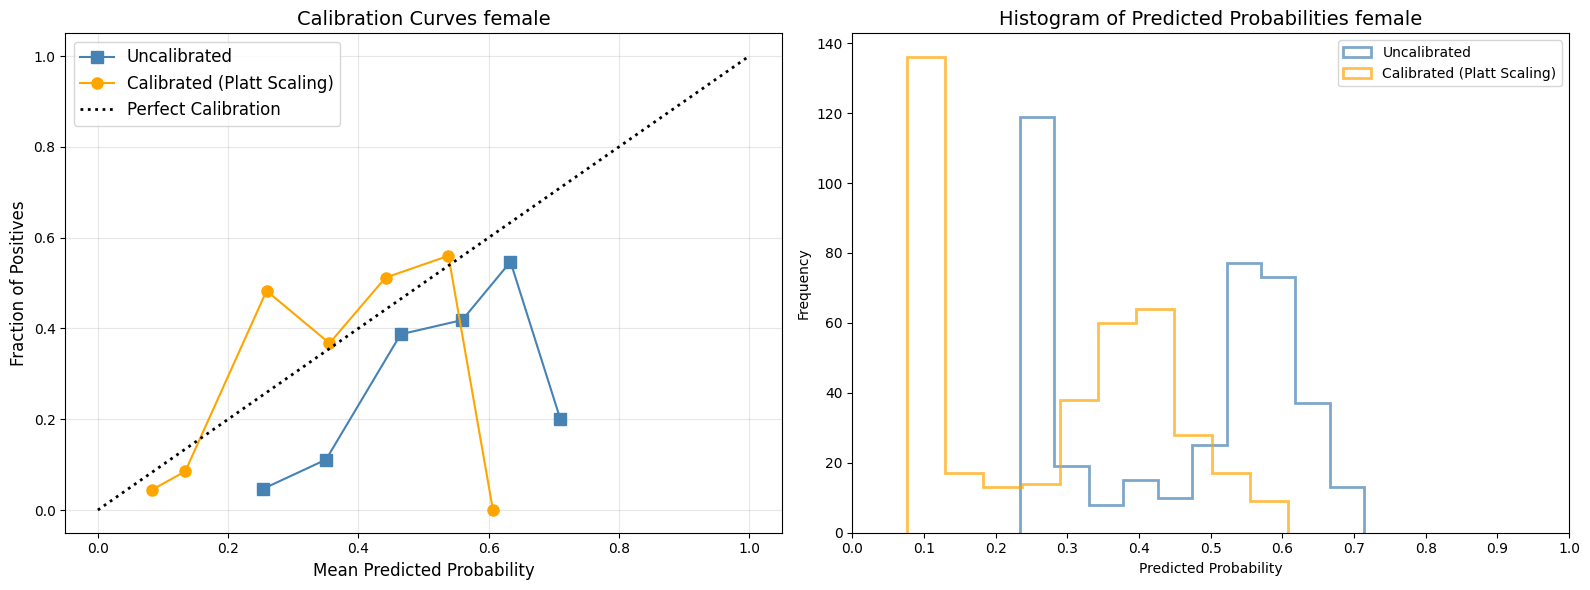

 ###### Model Evaluation ######
Negative Predictive Value (NPV): 0.8435
PPV (Precision): 0.4393
Sensitivity (Recall): 0.7192
Specificity: 0.6225
Balanced Accuracy: 0.6709
ROC AUC: 0.6709
Inverted F1 Score: 0.7164
Confusion Matrix: TN=221, FP=134, FN=41, TP=105

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.62      0.72       355
           1       0.44      0.72      0.55       146

    accuracy                           0.65       501
   macro avg       0.64      0.67      0.63       501
weighted avg       0.73      0.65      0.67       501

Brier score before calibration (male): 0.2086
Brier score after calibration (male): 0.1780


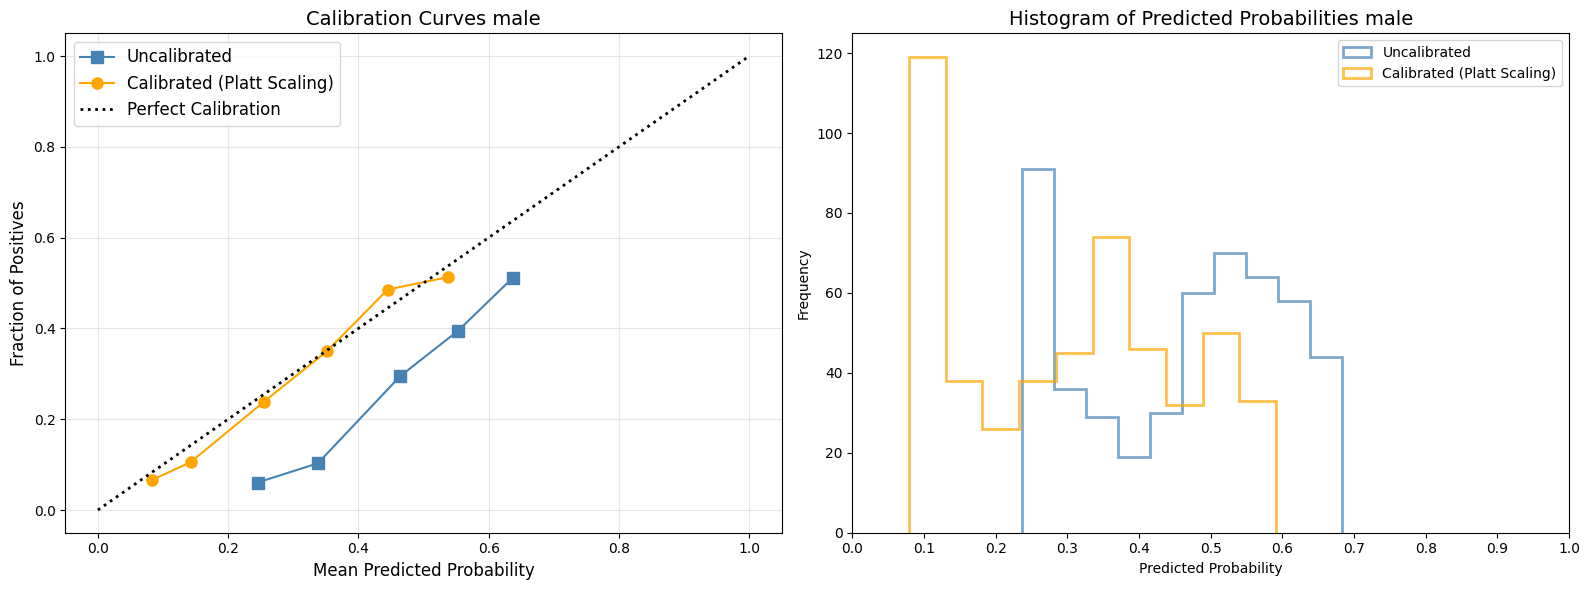

In [34]:
# calibrate the model using different methods
from sklearn.calibration import CalibratedClassifierCV

# Load the best model and evaluate it
model_types = ["female", "male"]
data_folder = os.path.join(os.getcwd(), "..", "data", "models")

for model_type in model_types:
    if model_type == "female":
        X_train, y_train, X_test, y_test, groups_train, groups_val, y_baseline = (
            x_full_f,
            y_full_f,
            X_test_f,
            y_test_f,
            groups_train_f,
            groups_val_f,
            y_pred_reg_f,
        )

        best_model = xgb_f_10

    elif model_type == "male":
        X_train, y_train, X_test, y_test, groups_train, groups_val, y_baseline = (
            x_full_m,
            y_full_m,
            X_test_m,
            y_test_m,
            groups_train_m,
            groups_val_m,
            y_pred_reg_m,
        )
        best_model = xgb_m_10

    y_proba, metrics = evaluate_model_comprehensive(best_model, X_test, y_test)

    calibrated_model = CalibratedClassifierCV(best_model, method="sigmoid", cv=10)
    calibrated_model.fit(X_train, y_train)

    cal_probs = calibrated_model.predict_proba(X_test)[:, 1]

    # Before calibration
    frac_pos_uncal, mean_pred_uncal = calibration_curve(y_test, y_proba, n_bins=10)

    # After calibration
    frac_pos_cal, mean_pred_cal = calibration_curve(y_test, cal_probs, n_bins=10)

    # Calculate and print Brier score
    brier_uncal = np.mean((y_test - y_proba) ** 2)
    brier_cal = np.mean((y_test - cal_probs) ** 2)
    print(f"Brier score before calibration ({model_type}): {brier_uncal:.4f}")
    print(f"Brier score after calibration ({model_type}): {brier_cal:.4f}")

    # Create subplots side by side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Define colors for consistency
    uncalibrated_color = "steelblue"
    calibrated_color = "orange"

    # Calibration curve subplot
    ax1.plot(
        mean_pred_uncal,
        frac_pos_uncal,
        "s-",
        label="Uncalibrated",
        markersize=8,
        color=uncalibrated_color,
    )
    ax1.plot(
        mean_pred_cal,
        frac_pos_cal,
        "o-",
        label="Calibrated (Platt Scaling)",
        markersize=8,
        color=calibrated_color,
    )
    ax1.plot([0, 1], [0, 1], "k:", linewidth=2, label="Perfect Calibration")

    ax1.set_xlabel("Mean Predicted Probability", fontsize=12)
    ax1.set_ylabel("Fraction of Positives", fontsize=12)
    ax1.set_title(f"Calibration Curves {model_type}", fontsize=14)
    ax1.legend(fontsize=12)
    ax1.grid(True, alpha=0.3)

    # Histogram subplot
    ax2.hist(
        y_proba,
        bins=10,
        alpha=0.7,
        label="Uncalibrated",
        color=uncalibrated_color,
        histtype="step",
        linewidth=2,
    )
    ax2.hist(
        cal_probs,
        bins=10,
        alpha=0.7,
        label="Calibrated (Platt Scaling)",
        color=calibrated_color,
        histtype="step",
        linewidth=2,
    )

    ax2.set_xlabel("Predicted Probability")
    ax2.set_ylabel("Frequency")
    ax2.set_title(f"Histogram of Predicted Probabilities {model_type}", fontsize=14)
    ax2.legend()
    ax2.set_xticks(np.arange(0, 1.1, 0.1))

    plt.tight_layout()
    plt.show()


In [35]:
# # Calibrate and save models
# data_folder = os.path.join(os.getcwd(), "..", "data", "models")

calibrated_model_f = CalibratedClassifierCV(xgb_f_10, method="sigmoid", cv=10)
calibrated_model_f.fit(x_full_f, y_full_f)

calibrated_model_m = CalibratedClassifierCV(xgb_m_10, method="sigmoid", cv=10)
calibrated_model_m.fit(x_full_m, y_full_m)

# # Save the original and calibrated models
# joblib.dump(xgb_f_10, os.path.join(data_folder, "argus_xgb_model_f.pkl"))
# joblib.dump(xgb_m_10, os.path.join(data_folder, "argus_xgb_model_m.pkl"))
# joblib.dump(
#     calibrated_model_f, os.path.join(data_folder, "argus_calibrated_xgb_model_f.pkl")
# )
# joblib.dump(
#     calibrated_model_m, os.path.join(data_folder, "argus_calibrated_xgb_model_m.pkl")
# )

,estimator,"XGBClassifier...ree=None, ...)"
,method,'sigmoid'
,cv,10
,n_jobs,None
,ensemble,'auto'
,objective,'binary:logistic'
,base_score,None
,booster,'gbtree'
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None


In [36]:
from sklearn.calibration import CalibratedClassifierCV

model_types = ["female", "male"]
calibration_results = {}

for model_type in model_types:
    if model_type == "female":
        X_train, y_train, X_test, y_test = x_full_f, y_full_f, X_test_f, y_test_f
        best_model = xgb_f_10
    elif model_type == "male":
        X_train, y_train, X_test, y_test = x_full_m, y_full_m, X_test_m, y_test_m
        best_model = xgb_m_10

    calibrated_model = CalibratedClassifierCV(best_model, method="sigmoid", cv=10)
    calibrated_model.fit(X_train, y_train)
    cal_probs = calibrated_model.predict_proba(X_test)[:, 1]

    calibration_results[model_type] = (y_test, cal_probs)

=== Calibration Metrics: Male (LOESS frac=0.6667) ===
Calibration Intercept (ideal=0): 0.031 (95% CI: -0.249–0.311)
Calibration Slope (ideal=1):     1.124 (95% CI: 0.834–1.414)
Brier Score (lower=better):      0.1780

=== Calibration Metrics: Female (LOESS frac=0.6667) ===
Calibration Intercept (ideal=0): 0.284 (95% CI: -0.049–0.617)
Calibration Slope (ideal=1):     1.262 (95% CI: 0.932–1.591)
Brier Score (lower=better):      0.1722



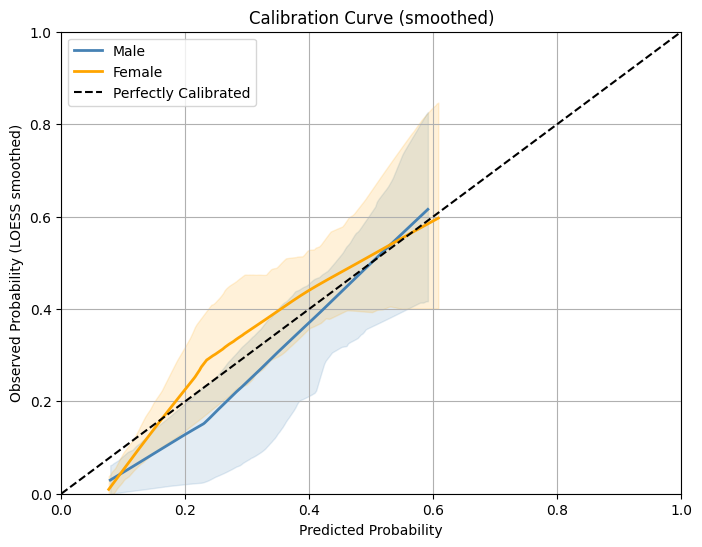

In [37]:
groups = {
    "Male": (*calibration_results["male"], "steelblue"),
    "Female": (*calibration_results["female"], "orange"),
}

results = plot_calibration_curve_smoothed(groups, method="loess", frac=0.6667, show_ci=True)

In [38]:
y_test_f.value_counts(dropna=False)

label
0    280
1    116
Name: count, dtype: int64

In [39]:
y_test_f.shape

(396,)

# Model performance

In [40]:
# test with ROC AUC
from sklearn.calibration import CalibratedClassifierCV

# Load the best model and evaluate it
model_types = ["female", "male"]
data_folder = os.path.join(os.getcwd(), "..", "data", "models")

for model_type in model_types:
    if model_type == "female":
        X_train, y_train, X_test, y_test, groups_train, groups_val, y_baseline = (
            x_full_f,
            y_full_f,
            X_test_f,
            y_test_f,
            groups_train_f,
            groups_val_f,
            y_pred_reg_f_proba,
        )

        best_model = calibrated_model_f

    elif model_type == "male":
        X_train, y_train, X_test, y_test, groups_train, groups_val, y_baseline = (
            x_full_m,
            y_full_m,
            X_test_m,
            y_test_m,
            groups_train_m,
            groups_val_m,
            y_pred_reg_m_proba,
        )
        best_model = calibrated_model_m

        print(
            f"Label distribution {model_type}: "
            f"{y_test.value_counts(dropna=False)}, {len(y_test)}, "
            f"{round(100 / len(y_test) * y_test.value_counts()[1], 2)}"
        )
    cal_probs = best_model.predict_proba(X_test)[:, 1]

    # set threshold and evaluate metrics
    print(f"Evaluating {model_type} data with threshold 0.15...")
    threshold = 0.15
    y_pred = (cal_probs >= threshold).astype(int)
    y_pred_baseline = (y_baseline >= threshold).astype(int)
    print(f"Calibrated predicted outcome distribution: {round(100 / len(y_pred) * y_pred.sum(), 2)}")
    evaluate_model_comprehensive_pred(y_pred, y_test, cal_probs)

    auc_score = roc_auc_score(y_test, cal_probs)
    auc_baseline = roc_auc_score(y_test, y_baseline)

    # ROC curve
    fpr, tpr, thres = roc_curve(y_test, cal_probs)
    fpr_baseline, tpr_baseline, thres_baseline = roc_curve(y_test, y_baseline)


Evaluating female data with threshold 0.15...
Calibrated predicted outcome distribution: 63.38
=== Model Evaluation ===

+----------------------+------------------+
| Metric               | Value (95% CI)   |
+======================+==================+
| ROC AUC              | 0.76 (0.70–0.81) |
+----------------------+------------------+
| AUPRC                | 0.49 (0.41–0.59) |
+----------------------+------------------+
| Sensitivity (Recall) | 0.95 (0.89–0.98) |
+----------------------+------------------+
| Specificity          | 0.50 (0.44–0.55) |
+----------------------+------------------+
| PPV (Precision)      | 0.44 (0.38–0.50) |
+----------------------+------------------+
| NPV                  | 0.96 (0.91–0.98) |
+----------------------+------------------+
| Balanced Accuracy    | 0.72 (0.67–0.77) |
+----------------------+------------------+
| Accuracy             | 0.63 (0.58–0.67) |
+----------------------+------------------+
| Inverted F1          | 0.65             |

## Feature importance

In [41]:
# Print all features used in the female and male XGBoost models
print("Female Model (xgb_f_10) Features:")
print(f"Total number of features: {len(xgb_f_10.feature_names_in_)}")
print("\nFeature names:")
for i, feature in enumerate(xgb_f_10.feature_names_in_, 1):
    print(f"{i:3d}. {feature}")

print("\n" + "=" * 60 + "\n")

print("Male Model (xgb_m_10) Features:")
print(f"Total number of features: {len(xgb_m_10.feature_names_in_)}")
print("\nFeature names:")
for i, feature in enumerate(xgb_m_10.feature_names_in_, 1):
    print(f"{i:3d}. {feature}")


Female Model (xgb_f_10) Features:
Total number of features: 35

Feature names:
  1. Age
  2. BMI
  3. DiastolicBP
  4. SystolicBP
  5. ALAT
  6. ASAT
  7. CRP
  8. Cholesterol
  9. GGT
 10. Glucose
 11. HDL Cholesterol
 12. Hemoglobine
 13. Kalium
 14. Kreatinine
 15. LD
 16. LDL Cholesterol
 17. Leucocyten
 18. MCH
 19. MCHC
 20. MCV
 21. Natrium
 22. TSH
 23. Triglyceriden
 24. Trombocyten
 25. eGFR (CKD-EPI)
 26. InjClsInfarction
 27. ST_deviation_index_Anterior
 28. ST_deviation_index_Inferior
 29. ST_deviation_index_Lateral
 30. T_morphology_score_Anterior
 31. T_morphology_score_Inferior
 32. T_morphology_score_Lateral
 33. Regional_ischemia_Anterior
 34. Regional_ischemia_Inferior
 35. Regional_ischemia_Lateral


Male Model (xgb_m_10) Features:
Total number of features: 35

Feature names:
  1. Age
  2. BMI
  3. DiastolicBP
  4. SystolicBP
  5. ALAT
  6. ASAT
  7. CRP
  8. Cholesterol
  9. GGT
 10. Glucose
 11. HDL Cholesterol
 12. Hemoglobine
 13. Kalium
 14. Kreatinine
 15. LD


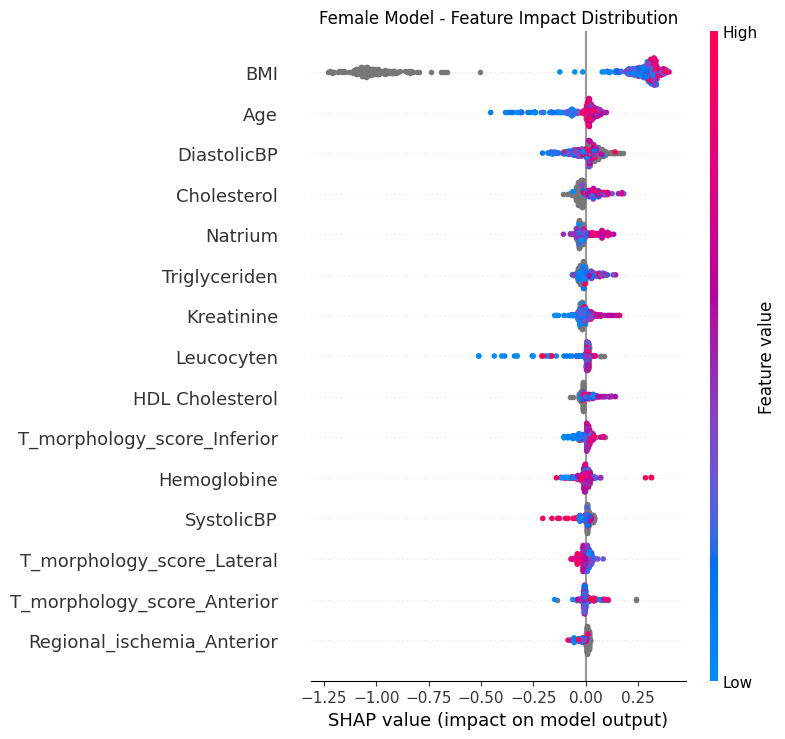

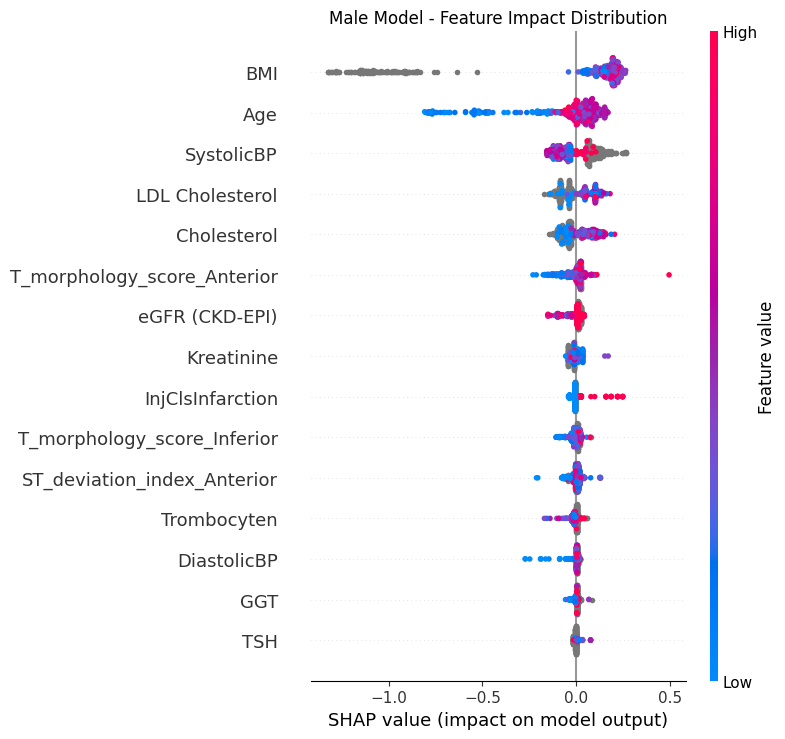

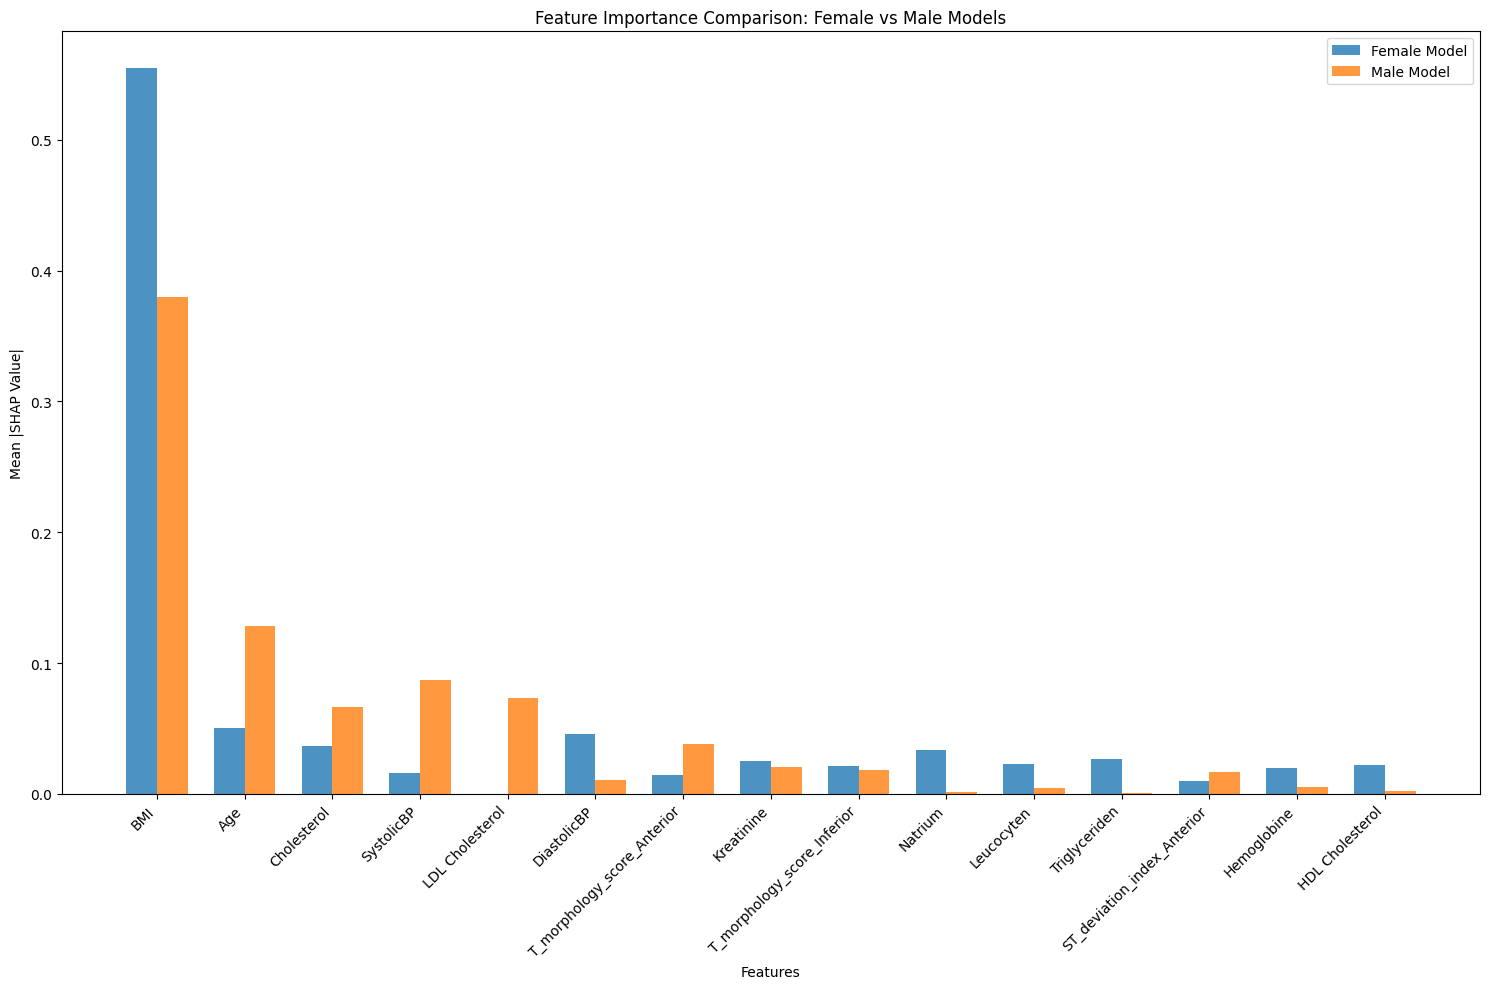

In [42]:
# SHAP values of models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap


def compute_shap_values(model, X):
    """Compute SHAP values for the given model and data."""
    explainer = shap.Explainer(model)
    shap_values = explainer(X)
    return shap_values


# Get SHAP values of xgb_f_10 and xgb_m_10
shap_values_f = compute_shap_values(xgb_f_10, X_test_f)
shap_values_m = compute_shap_values(xgb_m_10, X_test_m)

# Beeswarm plots (show distribution of impact)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_f, X_test_f, max_display=15, show=False)
plt.title("Female Model - Feature Impact Distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_m, X_test_m, max_display=15, show=False)
plt.title("Male Model - Feature Impact Distribution")
plt.tight_layout()
plt.show()

# Get feature importance for both models
feature_importance_f = np.abs(shap_values_f.values).mean(axis=0)
feature_importance_m = np.abs(shap_values_m.values).mean(axis=0)

# Create comparison DataFrame
comparison_df = pd.DataFrame(
    {
        "Feature": shap_values_f.feature_names,
        "Female_Importance": feature_importance_f,
        "Male_Importance": feature_importance_m,
    }
)

# Calculate difference and ratio
comparison_df["Difference"] = comparison_df["Female_Importance"] - comparison_df["Male_Importance"]
# Add a small epsilon to avoid division by zero
epsilon = 1e-8
comparison_df["Ratio_F_to_M"] = (comparison_df["Female_Importance"] + epsilon) / (
    comparison_df["Male_Importance"] + epsilon
)

# Sort by average importance
comparison_df["Avg_Importance"] = (comparison_df["Female_Importance"] + comparison_df["Male_Importance"]) / 2
comparison_df = comparison_df.sort_values("Avg_Importance", ascending=False)

# Visualize feature importance comparison
plt.figure(figsize=(15, 10))
top_features = comparison_df.head(15)

x = np.arange(len(top_features))
width = 0.35

plt.bar(
    x - width / 2,
    top_features["Female_Importance"],
    width,
    label="Female Model",
    alpha=0.8,
)
plt.bar(x + width / 2, top_features["Male_Importance"], width, label="Male Model", alpha=0.8)

plt.xlabel("Features")
plt.ylabel("Mean |SHAP Value|")
plt.title("Feature Importance Comparison: Female vs Male Models")
plt.xticks(x, top_features["Feature"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
